# Axe 6 : le graphe des parcours de procédure

Une entreprise en difficulté passe par plusieurs **étapes** : ouverture d'une sauvegarde, d'un redressement ou d'une liquidation, puis éventuellement un plan, une cession, une conversion en liquidation, et enfin une clôture. Chaque étape est publiée au BODACC.

L'idée : on reconstitue le **parcours** de chaque entreprise (la suite de ses étapes dans le temps), puis on construit un **graphe orienté** : un nœud par étape, une flèche de A vers B pondérée par le **nombre d'entreprises** passées de A à B. Ensuite on regarde les chemins les plus fréquents, les étapes « carrefours » (centralités, PageRank, comme au TP3), les délais, et ce que deviennent les redressements selon l'année d'ouverture.

### Lexique

| Terme | En clair |
|---|---|
| **Graphe orienté** | Les arêtes ont un sens (une flèche) : passer de « redressement » à « liquidation » n'est pas pareil que l'inverse. |
| **Poids d'une flèche** | Le nombre d'entreprises qui ont fait ce passage. |
| **Degré entrant / sortant pondéré** | Le nombre d'entreprises qui arrivent à une étape / qui en partent. |
| **PageRank** | L'importance d'une étape : une étape est importante si beaucoup de parcours y mènent, depuis des étapes elles-mêmes importantes. Sur un graphe orienté, c'est la centralité conseillée par la fiche. |
| **Cohorte** | Les entreprises dont la procédure s'est ouverte la même année. On suit chaque cohorte pendant le même temps (36 mois) pour pouvoir les comparer. |

### Les décisions

| Sujet | Décision | Qui |
|---|---|---|
| Étapes | 9 étapes à partir de la nature du jugement : sauvegarde, redressement judiciaire, liquidation judiciaire, plan de sauvegarde, plan de redressement, plan de cession, fin de procédure (l'entreprise est sauvée), clôture pour insuffisance d'actif, clôture pour extinction du passif. Les conversions et résolutions de plan mènent à l'étape de destination (ex. conversion en liquidation → liquidation). | Luka |
| Jugements « fourre-tout » | Les « Autre jugement d'ouverture / prononçant » sont **écartés** des parcours : on ne sait plus s'il s'agit d'un redressement ou d'une liquidation (leur texte n'est pas gardé dans `bodacc_clean`). | Luka |
| Parcours gardés | Seulement les entreprises (avec SIREN) dont le **premier événement est une ouverture** (sauvegarde, redressement ou liquidation). Les autres ont commencé leur procédure avant 2008, on ne voit qu'une partie de leur parcours. | Luka |
| Suivi des cohortes | On regarde où en est chaque entreprise **36 mois** après l'ouverture. Seules les ouvertures jusqu'à octobre 2023 ont 36 mois de recul. Priorité : plan de cession, puis liquidation, puis plan ou sauvetage. | Luka |
| Dessin du graphe | Seuls les passages faits par **au moins 500 entreprises** sont dessinés, pour la lisibilité. Les calculs et l'export gardent tous les passages. | Luka |

## 1. Chargement et étapes

In [1]:
import sys
sys.path.append("../../scripts")

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from data_utils import PROCESSED, free_memory, mem
import graphe_utils as gu

DASH = PROCESSED.parent / "dashboard"
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 90)

b = pd.read_parquet(PROCESSED / "bodacc_clean.parquet", columns=["siren", "date_evenement", "categorie", "nature"])
b = b[b["siren"].notna() & (b["categorie"] != "autre")]
print(len(b), "événements avec SIREN (hors catégorie « autre ») |", mem())

2234947 événements avec SIREN (hors catégorie « autre ») | process : 0.58 Go | disponible : 6.11 Go


In [2]:
ETAPES = ["Sauvegarde", "Redressement judiciaire", "Liquidation judiciaire", "Plan de sauvegarde",
          "Plan de redressement", "Plan de cession", "Fin de procédure (sauvée)",
          "Clôture : insuffisance d'actif", "Clôture : extinction du passif"]

def etape(categorie, nature):
    n = nature.lower()
    if n.startswith("autre jugement d'ouverture") or n.startswith("autre jugement prononçant"):
        return None                                   # type exact inconnu : écarté
    if categorie == "signal précoce":
        return "Sauvegarde"
    if categorie in ("entrée en défaillance", "aggravation"):
        if "liquidation" in n:
            return "Liquidation judiciaire"
        if "redressement" in n or "sortie de crise" in n:
            return "Redressement judiciaire"
        return None
    if categorie == "issue":
        if "cession" in n:
            return "Plan de cession"
        if "plan de sauvegarde" in n:
            return "Plan de sauvegarde"
        if "plan de redressement" in n or "plan de traitement" in n:
            return "Plan de redressement"
        if "extinction du passif" in n:
            return "Clôture : extinction du passif"
        if "mettant fin" in n or "clôture de la procédure de sauvegarde" in n:
            return "Fin de procédure (sauvée)"
        if "clôture" in n:
            return "Clôture : insuffisance d'actif"
    return None

natures = b[["categorie", "nature"]].drop_duplicates()
natures["étape"] = [etape(c, n) for c, n in zip(natures["categorie"], natures["nature"])]
b = b.merge(natures, on=["categorie", "nature"], how="left")
print("événements sans étape (écartés) :", b["étape"].isna().sum(), f"({b['étape'].isna().mean():.1%})")
b = b.dropna(subset=["étape"])
b["étape"].value_counts().reindex(ETAPES).to_frame("événements")

événements sans étape (écartés) : 48261 (2.2%)


,événements
étape,
Sauvegarde,22858
Redressement judiciaire,284529
Liquidation judiciaire,866394
Plan de sauvegarde,11304
Plan de redressement,70870
Plan de cession,17478
Fin de procédure (sauvée),4017
Clôture : insuffisance d'actif,891895
Clôture : extinction du passif,17341


### Observations

- On part de 2,23 millions d'événements avec SIREN. Seulement **2,2 %** n'ont pas d'étape (les jugements « fourre-tout ») et sont écartés.
- Les étapes les plus fréquentes sont les **clôtures pour insuffisance d'actif** (892 000) et les **liquidations** (866 000), loin devant les redressements (285 000). Les sauvegardes sont rares (23 000).

## 2. Les parcours

Pour chaque entreprise, on trie ses étapes par date et on enlève les répétitions (deux annonces de suite pour la même étape). Quand deux étapes ont la même date, on les range dans l'ordre logique (une ouverture avant une clôture).

In [3]:
ordre = {e: i for i, e in enumerate(ETAPES)}
b["ordre"] = b["étape"].map(ordre)
b = b.sort_values(["siren", "date_evenement", "ordre"])
b = b[b["étape"] != b.groupby("siren")["étape"].shift()]   # pas deux fois la même étape de suite

premiere = b.groupby("siren")["étape"].transform("first")
OUVERTURES = ["Sauvegarde", "Redressement judiciaire", "Liquidation judiciaire"]
garde = premiere.isin(OUVERTURES)
print(f"entreprises : {b['siren'].nunique():,} | dont parcours commençant par une ouverture : "
      f"{b.loc[garde, 'siren'].nunique():,}".replace(",", " "))
b = b[garde].drop(columns="ordre")
free_memory()
b.groupby("siren").size().describe().round(2)

entreprises : 1 097 675 | dont parcours commençant par une ouverture : 918 171


count    918171.00
mean          2.16
std           0.72
min           1.00
25%           2.00
50%           2.00
75%           2.00
max           9.00
dtype: float64

### Observations

- **918 171 entreprises** ont un parcours qui commence par une ouverture (sur 1,1 million). Les autres avaient commencé leur procédure avant 2008.
- Un parcours compte **2 étapes** dans la majorité des cas (médiane), et jusqu'à 9.

In [4]:
# Les 15 parcours complets les plus fréquents
parcours = b.groupby("siren")["étape"].agg(" → ".join)
top = parcours.value_counts()
pd.DataFrame({"entreprises": top.head(15), "part": (top.head(15) / len(parcours)).map("{:.1%}".format)})

,entreprises,part
étape,,
Liquidation judiciaire → Clôture : insuffisance d'actif,518685,56.5%
Redressement judiciaire → Liquidation judiciaire → Clôture : insuffisance d'actif,134697,14.7%
Liquidation judiciaire,88819,9.7%
Redressement judiciaire → Liquidation judiciaire,33446,3.6%
Redressement judiciaire → Plan de redressement,27445,3.0%
Redressement judiciaire → Plan de redressement → Liquidation judiciaire → Clôture : insuffisance d'actif,24576,2.7%
Redressement judiciaire,18234,2.0%
Redressement judiciaire → Clôture : insuffisance d'actif,7537,0.8%
Liquidation judiciaire → Clôture : extinction du passif,6859,0.7%


### Observations

- Le parcours de loin le plus fréquent est **liquidation → clôture pour insuffisance d'actif** : **56,5 %** des entreprises. Elles sont liquidées directement et ne remboursent pas leurs dettes.
- Le deuxième est **redressement → liquidation → clôture** (134 697 entreprises) : le sauvetage a échoué.
- Les parcours qui se terminent bien sont bien plus rares : **redressement → plan de redressement** (27 445), **sauvegarde → plan de sauvegarde** (6 121), **liquidation → clôture pour extinction du passif** (6 859, les dettes ont été payées).
- Certains parcours sont encore en cours : une liquidation sans clôture (88 819), un redressement sans suite (18 234).

## 3. Le graphe orienté des étapes

In [5]:
b["suivante"] = b.groupby("siren")["étape"].shift(-1)
b["date_suivante"] = b.groupby("siren")["date_evenement"].shift(-1)
transitions = b.dropna(subset=["suivante"])
flux = (transitions.groupby(["étape", "suivante"])
        .agg(entreprises=("siren", "size"),
             delai_median_mois=("date_suivante", lambda s: ((s - transitions.loc[s.index, "date_evenement"]).dt.days.median() / 30.44)))
        .reset_index().sort_values("entreprises", ascending=False))
flux["part des départs"] = flux["entreprises"] / flux.groupby("étape")["entreprises"].transform("sum")
G = nx.DiGraph()
for _, r in flux.iterrows():
    G.add_edge(r["étape"], r["suivante"], weight=int(r["entreprises"]))
print(G)
flux.head(20).round(2)

DiGraph with 9 nodes and 67 edges


,étape,suivante,entreprises,delai_median_mois,part des départs
21,Liquidation judiciaire,Clôture : insuffisance d'actif,703338,17.25,0.97
54,Redressement judiciaire,Liquidation judiciaire,180428,2.76,0.68
56,Redressement judiciaire,Plan de redressement,63576,13.07,0.24
38,Plan de redressement,Liquidation judiciaire,33250,27.00,0.93
65,Sauvegarde,Plan de sauvegarde,10780,12.84,0.52
20,Liquidation judiciaire,Clôture : extinction du passif,9492,28.78,0.01
55,Redressement judiciaire,Plan de cession,8523,4.83,0.03
23,Liquidation judiciaire,Plan de cession,7933,0.46,0.01
52,Redressement judiciaire,Clôture : insuffisance d'actif,7865,24.15,0.03
31,Plan de cession,Liquidation judiciaire,7443,1.61,0.54


### Observations

- Le graphe a **9 étapes** et **67 passages différents**, mais quelques-uns concentrent presque tout.
- Après un **redressement**, **68,5 %** des entreprises passent en liquidation, en **2,8 mois** en médiane (c'est la conversion à la fin de la période d'observation). **24,1 %** obtiennent un plan de redressement, en 13 mois en médiane. Seulement **3,2 %** passent par un plan de cession.
- Après un **plan de redressement**, **93 %** des passages suivants vont vers la liquidation, en **27 mois** en médiane : quand le plan échoue, c'est en général au bout de 2 ans.
- Une liquidation se clôture en **17 mois** en médiane.

In [6]:
cent = pd.DataFrame({
    "entrées (entreprises)": pd.Series(dict(G.in_degree(weight="weight"))),
    "sorties (entreprises)": pd.Series(dict(G.out_degree(weight="weight"))),
    "pagerank": pd.Series(nx.pagerank(G, weight="weight")),
    "intermédiarité": pd.Series(nx.betweenness_centrality(G)),
}).reindex(ETAPES)
cent.sort_values("pagerank", ascending=False).round(3)

,entrées (entreprises),sorties (entreprises),pagerank,intermédiarité
Liquidation judiciaire,235321,721758,0.415,0.016
Clôture : insuffisance d'actif,718634,6800,0.378,0.009
Redressement judiciaire,7179,263402,0.063,0.016
Plan de redressement,64871,35789,0.031,0.016
Clôture : extinction du passif,10458,148,0.029,0.003
Plan de sauvegarde,10844,4659,0.025,0.006
Plan de cession,16641,13726,0.023,0.003
Fin de procédure (sauvée),3562,611,0.018,0.009
Sauvegarde,106,20723,0.018,0.013


### Observations

- La **liquidation** a le plus fort PageRank (0,42), suivie de la **clôture pour insuffisance d'actif** (0,38) : presque tous les chemins finissent par passer par elles. Toutes les autres étapes sont sous 0,07.
- La liquidation reçoit 235 000 entreprises venues d'une autre étape (redressement, plan, sauvegarde), en plus de toutes les liquidations directes.

flèches dessinées : 21 sur 67


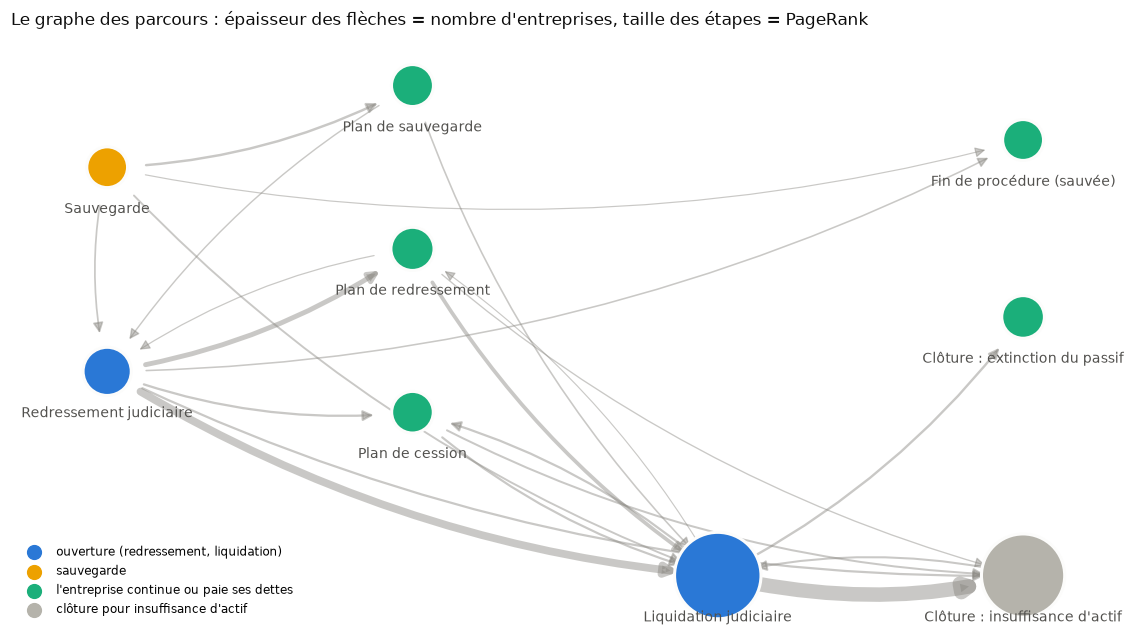

In [7]:
# Dessin du graphe : les étapes placées de gauche (ouverture) à droite (fin)
pos = {"Sauvegarde": (0, 2), "Redressement judiciaire": (0, 0.5), "Liquidation judiciaire": (2, -1),
       "Plan de sauvegarde": (1, 2.6), "Plan de redressement": (1, 1.4), "Plan de cession": (1, 0.2),
       "Fin de procédure (sauvée)": (3, 2.2), "Clôture : extinction du passif": (3, 0.9),
       "Clôture : insuffisance d'actif": (3, -1)}
# On ne dessine que les passages faits par au moins 500 entreprises (l'export garde tout)
H = G.edge_subgraph([(u, v) for u, v, d in G.edges(data=True) if d["weight"] >= 500]).copy()
print(f"flèches dessinées : {H.number_of_edges()} sur {G.number_of_edges()}")
fig, ax = plt.subplots(figsize=(13, 7))
poids = np.array([H[u][v]["weight"] for u, v in H.edges()])
largeur = 0.5 + 9 * np.sqrt(poids / poids.max())
couleur_noeud = {e: (gu.COULEURS[0] if e in OUVERTURES[1:] else gu.COULEURS[3] if e == "Sauvegarde"
                     else gu.COULEURS[2] if e.startswith(("Plan", "Fin", "Clôture : ext")) else gu.AUTRE) for e in G}
nx.draw_networkx_edges(H, pos, ax=ax, width=largeur, edge_color=gu.GRIS, alpha=0.45, arrowsize=14,
                       connectionstyle="arc3,rad=0.12", node_size=2600)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[600 + 2600 * cent.loc[e, "pagerank"] / cent["pagerank"].max() for e in G],
                       node_color=[couleur_noeud[e] for e in G], edgecolors="#fcfcfb", linewidths=2)
for e, (x, y) in pos.items():
    ax.annotate(e, (x, y), xytext=(0, -30), textcoords="offset points", ha="center", fontsize=9, color=gu.ENCRE)
for lib, c in [("ouverture (redressement, liquidation)", gu.COULEURS[0]), ("sauvegarde", gu.COULEURS[3]),
               ("l'entreprise continue ou paie ses dettes", gu.COULEURS[2]), ("clôture pour insuffisance d'actif", gu.AUTRE)]:
    ax.scatter([], [], s=80, color=c, label=lib)
ax.legend(frameon=False, loc="lower left", fontsize=8)
ax.set_axis_off()
ax.set_title("Le graphe des parcours : épaisseur des flèches = nombre d'entreprises, taille des étapes = PageRank",
             loc="left", fontsize=11, color=gu.TITRE)
plt.show()

### Observations

- Sur le dessin (passages d'au moins 500 entreprises), deux flèches écrasent toutes les autres : **liquidation → clôture** et **redressement → liquidation**.

## 4. Que deviennent les redressements ? (cohortes, suivi à 36 mois)

Pour chaque entreprise dont le parcours commence par un **redressement judiciaire**, on regarde ce qui s'est passé dans les **36 mois** après l'ouverture, dans cet ordre de priorité : un **plan de cession** (l'activité est reprise par un tiers, même si l'entreprise d'origine est ensuite liquidée), sinon une **liquidation**, sinon un **plan ou un sauvetage** (plan de redressement, fin de procédure, dettes payées), sinon **pas encore d'issue** (toujours en période d'observation, ou issue pas encore publiée).

In [8]:
debut = b.groupby("siren").agg(premiere=("étape", "first"), ouverture=("date_evenement", "first"))
rj = debut[debut["premiere"] == "Redressement judiciaire"].copy()
rj = rj[rj["ouverture"] <= pd.Timestamp("2026-10-31") - pd.DateOffset(months=36)]
suivi = b.merge(rj[["ouverture"]], left_on="siren", right_index=True)
suivi = suivi[suivi["date_evenement"] <= suivi["ouverture"] + pd.DateOffset(months=36)]

def issue(etapes):
    e = set(etapes)
    if "Plan de cession" in e:          # l'activité est reprise, même si l'entreprise d'origine est ensuite liquidée
        return "plan de cession"
    if "Liquidation judiciaire" in e:
        return "liquidation"
    if "Plan de redressement" in e or "Fin de procédure (sauvée)" in e or "Clôture : extinction du passif" in e:
        return "plan ou sauvetage"
    return "pas encore d'issue"

rj["issue à 36 mois"] = suivi.groupby("siren")["étape"].agg(issue)
rj["année d'ouverture"] = rj["ouverture"].dt.year
cohortes = pd.crosstab(rj["année d'ouverture"], rj["issue à 36 mois"], normalize="index").mul(100)
cohortes["redressements ouverts"] = rj["année d'ouverture"].value_counts()
cohortes = cohortes.loc[2008:2023]
cohortes.round(1)

issue à 36 mois,liquidation,pas encore d'issue,plan de cession,plan ou sauvetage,redressements ouverts
année d'ouverture,,,,,
2008,72.8,5.8,5.1,16.3,15768
2009,71.5,3.6,5.8,19.2,17322
2010,71.6,3.7,5.3,19.5,16597
2011,70.9,4.8,5.3,19.0,16477
2012,70.6,5.0,5.0,19.3,16445
2013,69.1,4.1,5.4,21.3,16432
2014,67.3,5.0,5.3,22.4,15947
2015,68.2,5.8,4.6,21.4,16256
2016,69.1,5.1,4.3,21.5,15026


### Observations

- Pour les redressements ouverts de 2008 à 2023, environ **7 sur 10** finissent en **liquidation** dans les 36 mois (64,7 % à 72,8 % selon l'année).
- La part qui obtient un **plan ou un sauvetage** monte de **16,3 %** (2008) à environ **22 %** (2013 à 2020), puis **redescend** à 16,6 à 18,2 % pour les ouvertures de 2021 à 2023.
- Les **plans de cession** concernent 4 à 6 % des redressements.
- L'année **2020** se distingue : la plus faible part de liquidation (64,7 %), et deux fois moins de redressements ouverts (7 132 contre 14 257 en 2019).

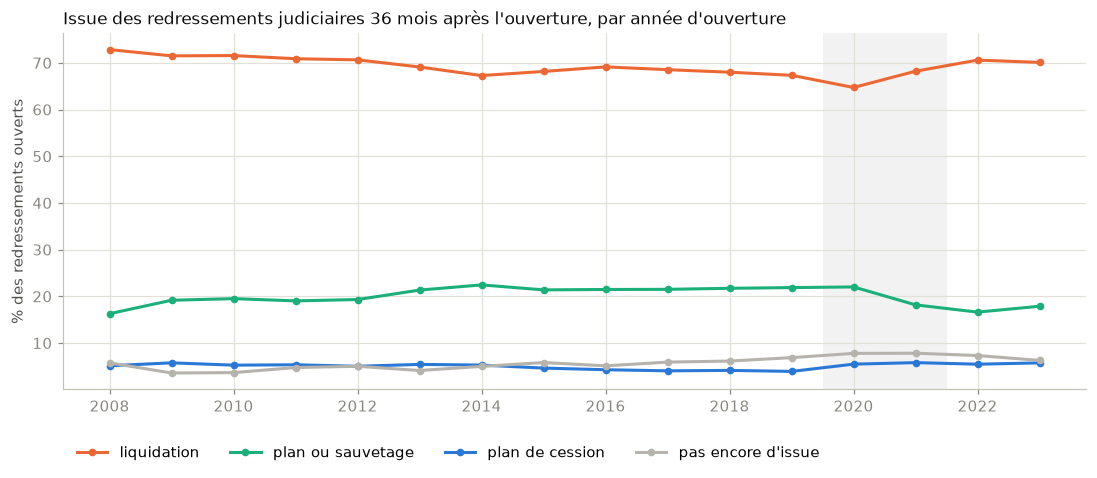

In [9]:
ISSUES = ["liquidation", "plan ou sauvetage", "plan de cession", "pas encore d'issue"]
fig, ax = plt.subplots(figsize=(12, 4.2))
for issue_, couleur in zip(ISSUES, [gu.COULEURS[1], gu.COULEURS[2], gu.COULEURS[0], gu.AUTRE]):
    ax.plot(cohortes.index, cohortes[issue_], lw=2, marker="o", ms=4, color=couleur, label=issue_)
ax.axvspan(2019.5, 2021.5, color=gu.GRIS, alpha=0.1, lw=0)
ax.set_ylabel("% des redressements ouverts")
ax.set_xticks(range(2008, 2024, 2))
ax.set_title("Issue des redressements judiciaires 36 mois après l'ouverture, par année d'ouverture", loc="left",
             fontsize=11, color=gu.TITRE)
ax.legend(frameon=False, ncol=4, loc="upper left", bbox_to_anchor=(0, -0.12))
plt.show()

## 5. Les délais entre les étapes

In [10]:
principales = flux[flux["entreprises"] >= 1000].copy()
principales["passage"] = principales["étape"] + " → " + principales["suivante"]
principales.set_index("passage")[["entreprises", "délai médian (mois)" if False else "delai_median_mois"]] \
    .rename(columns={"delai_median_mois": "délai médian (mois)"}).round(1)

,entreprises,délai médian (mois)
passage,,
Liquidation judiciaire → Clôture : insuffisance d'actif,703338,17.2
Redressement judiciaire → Liquidation judiciaire,180428,2.8
Redressement judiciaire → Plan de redressement,63576,13.1
Plan de redressement → Liquidation judiciaire,33250,27.0
Sauvegarde → Plan de sauvegarde,10780,12.8
Liquidation judiciaire → Clôture : extinction du passif,9492,28.8
Redressement judiciaire → Plan de cession,8523,4.8
Liquidation judiciaire → Plan de cession,7933,0.5
Redressement judiciaire → Clôture : insuffisance d'actif,7865,24.1


### Observations

- Les passages rapides sont ceux qui ferment une période d'observation : redressement → liquidation (**2,8 mois**), redressement → plan de cession (**4,8 mois**), plan de cession → liquidation (1,6 mois).
- Les passages lents sont ceux qui suivent un plan : plan de redressement → liquidation (**27 mois**), plan de cession → clôture (37 mois).

## 6. Avant et après le Covid

On compare les passages pour les procédures ouvertes **avant** (2016-2019) et **après** (2021-2023) le Covid. Les deux périodes ont au moins 36 mois de recul.

In [11]:
debut["année"] = debut["ouverture"].dt.year
def parts(annees):
    s = debut.index[debut["année"].isin(annees)]
    t = transitions[transitions["siren"].isin(s)]
    f = t.groupby(["étape", "suivante"]).size()
    return f / f.groupby(level=0).transform("sum")
comparaison = pd.DataFrame({"2016-2019": parts(range(2016, 2020)), "2021-2023": parts(range(2021, 2024))}).fillna(0)
comparaison["écart (points)"] = 100 * (comparaison["2021-2023"] - comparaison["2016-2019"])
comparaison = comparaison[comparaison.max(axis=1) > 0.02]
comparaison.loc[["Redressement judiciaire", "Sauvegarde", "Liquidation judiciaire"]].mul(
    {"2016-2019": 100, "2021-2023": 100, "écart (points)": 1}).round(1)

2016-2019  2021-2023  \
étape                   suivante                                               
Redressement judiciaire Clôture : insuffisance d'actif        3.6        3.8   
                        Fin de procédure (sauvée)             1.2        1.4   
                        Liquidation judiciaire               67.4       70.4   
                        Plan de cession                       2.9        2.9   
                        Plan de redressement                 24.6       21.4   
Sauvegarde              Fin de procédure (sauvée)             3.7        2.6   
                        Liquidation judiciaire               23.0       25.0   
                        Plan de redressement                  2.5        1.9   
                        Plan de sauvegarde                   55.1       48.0   
                        Redressement judiciaire              14.2       21.5   
Liquidation judiciaire  Clôture : insuffisance d'actif       97.8       97.6   
                        Plan de cession                       0.8        1.2   

                                                        écart (points)  
étape                   suivante                                        
Redressement judiciaire Clôture : insuffisance d'actif             0.2  
                        Fin de procédure (sauvée)                  0.2  
                        Liquidation judiciaire                     2.9  
                        Plan de cession                            0.0  
                        Plan de redressement                      -3.3  
Sauvegarde              Fin de procédure (sauvée)                 -1.1  
                        Liquidation judiciaire                     2.0  
                        Plan de redressement                      -0.6  
                        Plan de sauvegarde                        -7.1  
                        Redressement judiciaire                    7.3  
Liquidation judiciaire  Clôture : insuffisance d'actif            -0.2  
                        Plan de cession                            0.4

### Observations

- Après le Covid (procédures ouvertes en 2021-2023), un **redressement** mène **un peu plus souvent à la liquidation** (70,4 % contre 67,4 % avant) et **un peu moins souvent à un plan** (21,4 % contre 24,6 %).
- Pour les **sauvegardes**, l'écart est plus net : moins de plans de sauvegarde (**48,0 %** contre 55,1 %) et plus de passages en **redressement** (**21,5 %** contre 14,2 %).

## 7. Export pour le dashboard

In [12]:
noeuds_df = cent.reset_index().rename(columns={"index": "etape"})
noeuds_df["x"] = noeuds_df["etape"].map(lambda e: pos[e][0])
noeuds_df["y"] = noeuds_df["etape"].map(lambda e: pos[e][1])
flux.rename(columns={"étape": "source", "suivante": "cible", "part des départs": "part_des_departs"}).to_parquet(
    DASH / "parcours_aretes.parquet", index=False)
noeuds_df.to_parquet(DASH / "parcours_noeuds.parquet", index=False)
cohortes.reset_index().to_parquet(DASH / "parcours_cohortes_rj.parquet", index=False)
top.head(30).rename_axis("parcours").reset_index(name="entreprises").to_parquet(DASH / "parcours_top.parquet", index=False)
print("export : parcours_noeuds, parcours_aretes, parcours_cohortes_rj, parcours_top")

export : parcours_noeuds, parcours_aretes, parcours_cohortes_rj, parcours_top
